accelerometer: 628 samples, estimated rate 25.0 Hz
gyroscope: 628 samples, estimated rate 25.0 Hz


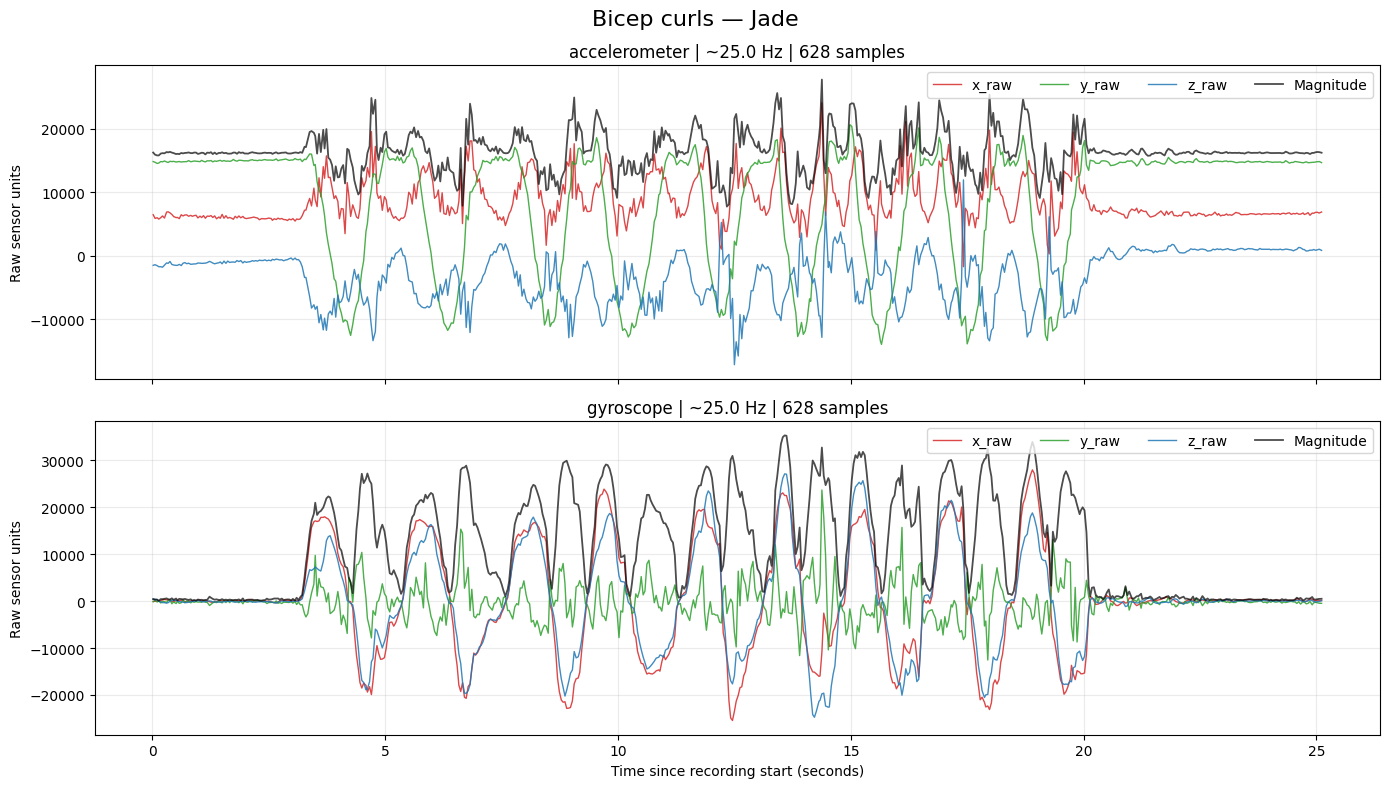

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = Path(
    "/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo/Data/new_watch/"
    "VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193043Z.csv"
)

df = pd.read_csv(path)

# Use the watch's measurement timestamps, not phone arrival times.
t0 = df["watch_timestamp_ms"].min()
df["time_s"] = (df["watch_timestamp_ms"] - t0) / 1000

# Keep neutral labels until the protocol mapping is confirmed.
streams = {
    1: "accelerometer",
    2: "gyroscope",
}

fig, axes = plt.subplots(
    len(streams), 1, figsize=(14, 8), sharex=True
)

for ax, (sensor_type, label) in zip(axes, streams.items()):
    data = (
        df.loc[df["type"] == sensor_type]
        .sort_values("watch_timestamp_ms")
        .copy()
    )

    if data.empty:
        ax.set_title(f"{label}: no data")
        continue

    dt = data["watch_timestamp_ms"].diff() / 1000
    positive_dt = dt[dt > 0]
    fs = 1 / positive_dt.median() if not positive_dt.empty else np.nan

    for column, color in zip(
        ["x_raw", "y_raw", "z_raw"],
        ["tab:red", "tab:green", "tab:blue"],
    ):
        ax.plot(
            data["time_s"], data[column],
            label=column, color=color, linewidth=1, alpha=0.85
        )

    magnitude = np.sqrt(
        (data[["x_raw", "y_raw", "z_raw"]].astype(float) ** 2).sum(axis=1)
    )
    ax.plot(
        data["time_s"], magnitude,
        label="Magnitude", color="black", linewidth=1.3, alpha=0.7
    )

    ax.set_title(f"{label} | ~{fs:.1f} Hz | {len(data)} samples")
    ax.set_ylabel("Raw sensor units")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right", ncol=4)

    print(f"{label}: {len(data)} samples, estimated rate {fs:.1f} Hz")

axes[-1].set_xlabel("Time since recording start (seconds)")
fig.suptitle("Bicep curls — Jade", fontsize=16)
plt.tight_layout()
plt.show()

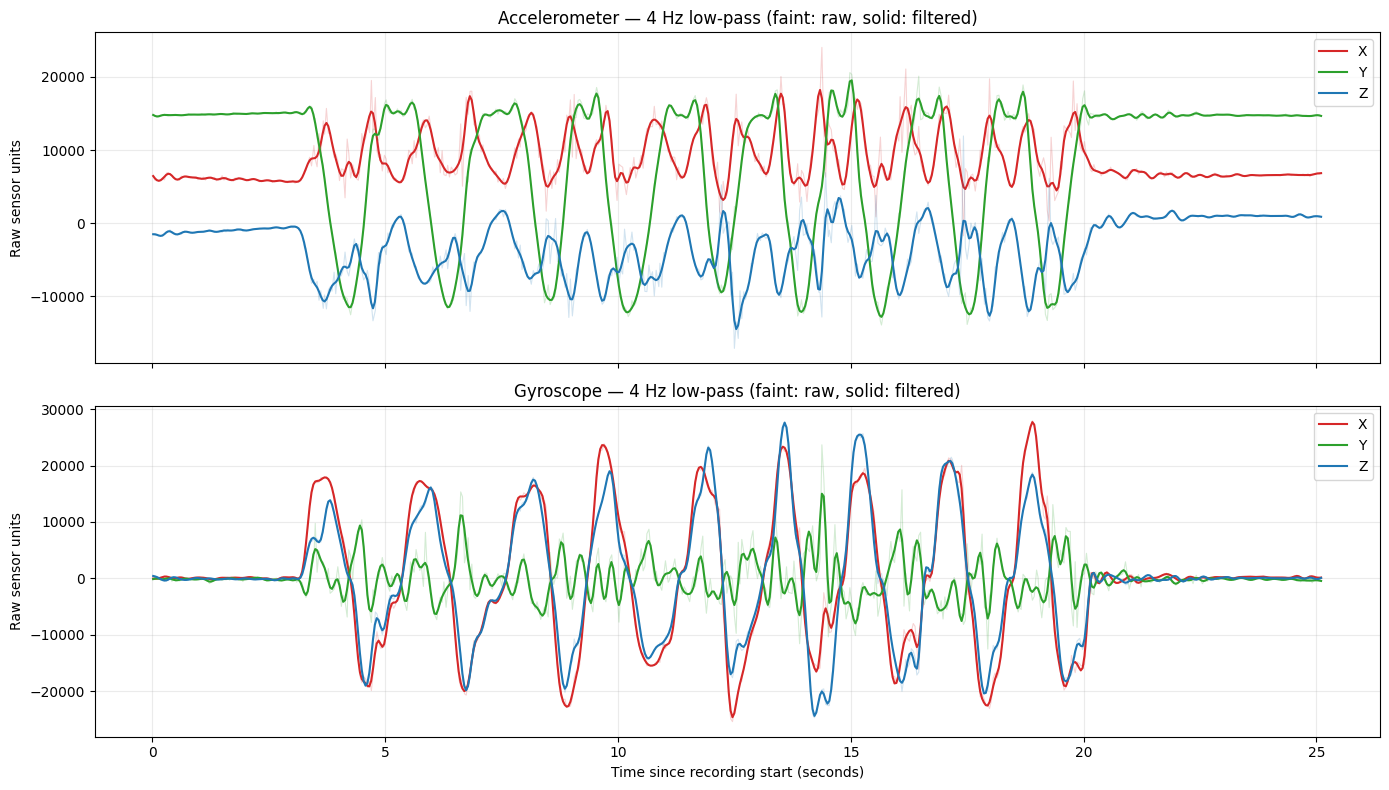

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

cutoff_hz = 4.0  # Lower = more smoothing
sensor_names = {1: "Accelerometer", 2: "Gyroscope"}
filtered_streams = {}

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
t0 = df["watch_timestamp_ms"].min() / 1000

for ax, sensor_type in zip(axes, [1, 2]):
    data = (
        df.loc[df["type"] == sensor_type]
        .sort_values("watch_timestamp_ms")
        .drop_duplicates("watch_timestamp_ms")
        .copy()
    )

    t = data["watch_timestamp_ms"].to_numpy(dtype=float) / 1000
    dt = np.median(np.diff(t))
    fs = 1 / dt

    # Resample onto an evenly spaced timeline for filtering.
    t_uniform = np.arange(t[0], t[-1] + dt * 0.01, dt)
    time_s = t_uniform - t0

    sos = butter(4, cutoff_hz, btype="lowpass", fs=fs, output="sos")
    result = {"time_s": time_s}

    for column, color in zip(
        ["x_raw", "y_raw", "z_raw"],
        ["tab:red", "tab:green", "tab:blue"],
    ):
        raw = data[column].to_numpy(dtype=float)
        regular = np.interp(t_uniform, t, raw)
        smoothed = sosfiltfilt(sos, regular)

        result[column.replace("_raw", "_filtered")] = smoothed

        ax.plot(t - t0, raw, color=color, alpha=0.2, linewidth=0.8)
        ax.plot(
            time_s, smoothed, color=color, linewidth=1.5,
            label=column.replace("_raw", "").upper()
        )

    filtered_streams[sensor_type] = result

    if np.max(np.diff(t)) > 2 * dt:
        print(
            f"Warning: {sensor_names[sensor_type]} has timestamp gaps. "
            "Interpolation bridges these gaps; inspect before analysis."
        )

    ax.set_title(
        f"{sensor_names[sensor_type]} — {cutoff_hz:g} Hz low-pass "
        "(faint: raw, solid: filtered)"
    )
    ax.set_ylabel("Raw sensor units")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Time since recording start (seconds)")
plt.tight_layout()
plt.show()

Stillness check failed: no gyro bias correction applied.
Final rep confirmed: 18.58–20.26 seconds


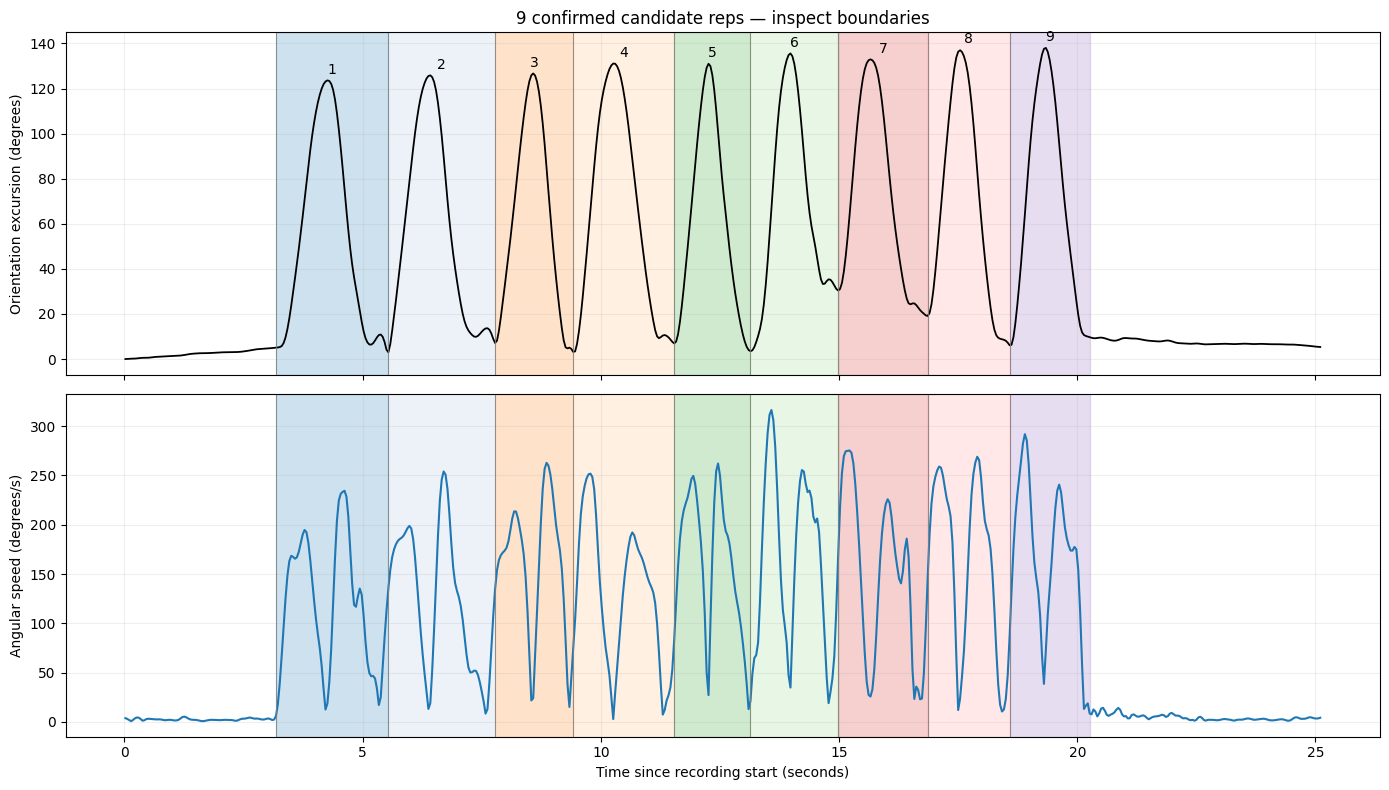

Sampling rate: 25.00 Hz
Six features; start_s/end_s are metadata, not features.
Gray hatched tail is excluded pending boundary review.
Completion error is estimated watch rotation, not joint angle.
Frequency ratio is exploratory: firmware lacks pre-downsampling anti-aliasing.


,rep,start_s,end_s,completion_error_deg,gyro_mean_deg_s,gyro_peak_deg_s,gyro_std_deg_s,accel_magnitude_std_g,gyro_high_low_power_ratio
0,1,3.18,5.54,8.2011,117.8456,234.4002,65.7022,0.1613,0.0500
1,2,5.54,7.78,5.3106,122.9878,253.9448,70.7074,0.1646,0.0104
2,3,7.78,9.42,4.8614,158.1379,262.7095,68.1372,0.2150,0.0329
3,4,9.42,11.54,5.6327,128.6523,251.7746,71.9160,0.1735,0.0215
4,5,11.54,13.14,6.1404,160.6877,262.0433,71.8731,0.2440,0.1954
5,6,13.14,14.98,28.8250,159.7039,316.2646,88.2082,0.2645,0.0808
6,7,14.98,16.86,11.9089,148.7423,275.2275,82.0533,0.2264,0.0613
7,8,16.86,18.58,15.9330,159.8670,268.8858,87.3072,0.2341,0.0317
8,9,18.58,20.26,5.1771,162.4384,291.7630,77.5746,0.2311,0.0755


,start_s,end_s,status


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy.signal import butter, sosfiltfilt, periodogram
from scipy.spatial.transform import Rotation
from IPython.display import display

# Settings adapted from the previous orientation-based detector.
CUTOFF_HZ = 4.0
STILL_SECONDS = 2.0
START_RISE_DEG = 15.0
REVERSAL_DEG = 8.0

# Confirmed watch protocol:
# Type 1: accelerometer, raw × 0.000061 = g
# Type 2: gyroscope, raw × 0.00875 = degrees/second
if df["protocol_session_id"].nunique() != 1:
    raise ValueError("Select one recording session first.")

t0 = df["watch_timestamp_ms"].min() / 1000
streams = {}

for sensor_type, scale in [(1, 0.000061), (2, 0.00875)]:
    data = df.loc[df["type"] == sensor_type].copy()
    columns = ["watch_timestamp_ms", "x_raw", "y_raw", "z_raw"]

    if data.empty or not data["validity"].eq(1).all():
        raise ValueError(f"Sensor {sensor_type}: missing or invalid data.")
    if not np.isfinite(data[columns].to_numpy(dtype=float)).all():
        raise ValueError("Nonfinite sensor values found.")

    ts = data["watch_timestamp_ms"].to_numpy(dtype=float) / 1000 - t0
    if np.any(np.diff(ts) <= 0):
        raise ValueError("Duplicate or out-of-order timestamps found.")

    dt = np.median(np.diff(ts))
    if np.max(np.diff(ts)) > 1.5 * dt:
        raise ValueError("Timestamp gap found. Split into continuous blocks first.")

    values = data[["x_raw", "y_raw", "z_raw"]].to_numpy() * scale
    streams[sensor_type] = (ts, values, dt)

fs = 1 / streams[2][2]
if not np.isclose(streams[1][2], streams[2][2], rtol=0.05):
    raise ValueError("Accelerometer and gyroscope sampling rates differ.")
if fs / 2 <= 8:
    raise ValueError("Sampling rate is too low for the 3–8 Hz power band.")

# Align both sensors onto the same evenly spaced timeline.
t = np.arange(
    max(streams[1][0][0], streams[2][0][0]),
    min(streams[1][0][-1], streams[2][0][-1]) + 1e-8,
    1 / fs,
)

def align(sensor_type):
    ts, values, _ = streams[sensor_type]
    return np.column_stack([
        np.interp(t, ts, values[:, axis]) for axis in range(3)
    ])

accel_raw_g = align(1)
gyro_raw_dps = align(2)

# Apply gyro bias correction only if the lead-in passes the old stillness check.
lead = t < t[0] + STILL_SECONDS
stationary_ok = (
    lead.sum() >= 10
    and np.std(np.linalg.norm(accel_raw_g[lead], axis=1)) <= 0.03
    and np.max(np.linalg.norm(gyro_raw_dps[lead], axis=1)) <= 5
)

if stationary_ok:
    gyro_raw_dps -= gyro_raw_dps[lead].mean(axis=0)
else:
    print("Stillness check failed: no gyro bias correction applied.")

# Filter axes for orientation estimation and time-domain features.
# Preserve unfiltered gyro for the frequency-power ratio.
sos = butter(4, CUTOFF_HZ, fs=fs, btype="lowpass", output="sos")
accel_g = sosfiltfilt(sos, accel_raw_g, axis=0)
gyro_dps = sosfiltfilt(sos, gyro_raw_dps, axis=0)

# Estimate 3D orientation using gyro integration and gated gravity correction.
x, y, z = accel_g[0]
orientation = Rotation.from_euler(
    "xyz",
    [np.arctan2(y, z), np.arctan2(-x, np.hypot(y, z)), 0],
)
initial_orientation = orientation
quaternions = [orientation.as_quat()]
excursions = [0.0]

for i in range(1, len(t)):
    omega = np.deg2rad((gyro_dps[i - 1] + gyro_dps[i]) / 2)
    accel_norm = np.linalg.norm(accel_g[i])

    if 0.85 <= accel_norm <= 1.15:
        omega += 0.5 * np.cross(
            accel_g[i] / accel_norm,
            orientation.inv().apply([0, 0, 1]),
        )

    orientation = orientation * Rotation.from_rotvec(
        omega * (t[i] - t[i - 1])
    )
    quaternions.append(orientation.as_quat())
    excursions.append(
        np.rad2deg((initial_orientation.inv() * orientation).magnitude())
    )

quaternions = np.asarray(quaternions)

# Approximately 100 ms trailing smoothing, adapted to the measured sample rate.
history = deque(maxlen=max(1, round(0.1 * fs)))
excursion = []
for value in excursions:
    history.append(value)
    excursion.append(np.mean(history))
excursion = np.asarray(excursion)

# Previous trough-to-trough hysteresis detector.
# A return is confirmed when the next repetition begins.
mode = "seek"
low = high = start = None
candidates = []

for i in np.flatnonzero(~lead):
    value = excursion[i]

    if low is None:
        low = (i, value)
        continue

    if mode in ("seek", "rise"):
        if value < low[1]:
            low = (i, value)

        if mode == "seek" and value - low[1] >= START_RISE_DEG:
            start, high, mode = low[0], (i, value), "rise"

        elif mode == "rise":
            if high is None or value > high[1]:
                high = (i, value)
            if high[1] - value >= REVERSAL_DEG:
                low, mode = (i, value), "fall"

    else:
        if value < low[1]:
            low = (i, value)
        if value - low[1] >= REVERSAL_DEG:
            candidates.append((start, low[0]))
            start, high, mode = low[0], (i, value), "rise"

# Trim initial idle time before the first repetition.
speed_all = np.linalg.norm(gyro_dps, axis=1)
rest_speed = speed_all[lead]
onset_threshold = max(
    10.0,
    np.median(rest_speed)
    + 6 * np.median(np.abs(rest_speed - np.median(rest_speed))),
)

if candidates:
    a, b = candidates[0]
    hold = max(2, int(np.ceil(0.12 * fs)))
    for k in range(a, b - hold + 1):
        if np.all(speed_all[k:k + hold] > onset_threshold):
            candidates[0] = (max(a, k - 1), b)
            break

# Confirm the last repetition using return-to-start + sustained stillness.
# These are adjustable prototype settings, not clinical thresholds.
FINAL_RETURN_TOLERANCE_DEG = 15.0
FINAL_STILL_SPEED_DPS = 15.0
FINAL_STILL_SECONDS = 0.5

if start is not None and mode == "fall" and high is not None:
    peak_index, peak_value = high

    # Require a substantial rise followed by a substantial return.
    substantial_rise = (
        peak_value - excursion[start] >= START_RISE_DEG
    )

    near_start = (
        np.abs(excursion - excursion[start])
        <= FINAL_RETURN_TOLERANCE_DEG
    )
    substantial_return = (
        peak_value - excursion >= REVERSAL_DEG
    )
    slow = speed_all <= FINAL_STILL_SPEED_DPS

    settled = near_start & substantial_return & slow
    settled[:peak_index + 1] = False

    settle_start = None
    final_end = None

    if substantial_rise:
        for i in range(peak_index + 1, len(t)):
            if settled[i]:
                if settle_start is None:
                    settle_start = i

                if t[i] - t[settle_start] >= FINAL_STILL_SECONDS:
                    final_end = settle_start
                    break
            else:
                settle_start = None

    if final_end is not None:
        # Apply the same segmentation checks used for the other reps.
        valid_length = 0.6 <= t[final_end] - t[start] <= 8
        valid_excursion = (
            np.ptp(excursion[start:final_end + 1]) >= START_RISE_DEG
        )

        if valid_length and valid_excursion:
            candidates.append((start, final_end))
            print(
                f"Final rep confirmed: "
                f"{t[start]:.2f}–{t[final_end]:.2f} seconds"
            )

            # Prevent this completed rep from being marked as an unconfirmed tail.
            start = None
            mode = "seek"
        else:
            print("Final movement failed segmentation checks; left for review.")
    else:
        print("Final rep not confirmed: no sustained return-and-stillness period.")
        
# Calculate six features per confirmed candidate repetition.
feature_columns = [
    "completion_error_deg",
    "gyro_mean_deg_s",
    "gyro_peak_deg_s",
    "gyro_std_deg_s",
    "accel_magnitude_std_g",
    "gyro_high_low_power_ratio",
]

rows, review_rows, accepted = [], [], []

for a, b in candidates:
    # Duration is used only for segmentation checks, not as a feature.
    reasons = []
    if not 0.6 <= t[b] - t[a] <= 8:
        reasons.append("Outside previous 0.6–8 s segmentation bounds")
    if np.ptp(excursion[a:b + 1]) < START_RISE_DEG:
        reasons.append("Insufficient orientation excursion")

    if reasons:
        review_rows.append({
            "start_s": t[a],
            "end_s": t[b],
            "status": "; ".join(reasons),
        })
        continue

    section = slice(a, b + 1)
    speed = np.linalg.norm(gyro_dps[section], axis=1)

    # Smallest 3D rotation between estimated start/end orientations.
    completion_error = np.rad2deg(
        (
            Rotation.from_quat(quaternions[a]).inv()
            * Rotation.from_quat(quaternions[b])
        ).magnitude()
    )

    # Use unfiltered gyro magnitude to preserve high-frequency content.
    raw_speed = np.linalg.norm(gyro_raw_dps[section], axis=1)
    frequencies, power = periodogram(
        raw_speed,
        fs=fs,
        window="hann",
        detrend="constant",
        scaling="spectrum",
    )
    low_power = power[
        (frequencies >= 0.1) & (frequencies <= 2)
    ].sum()
    high_power = power[
        (frequencies >= 3) & (frequencies <= 8)
    ].sum()

    rep_id = len(rows) + 1
    rows.append({
        "rep": rep_id,
        "start_s": t[a],
        "end_s": t[b],
        "completion_error_deg": completion_error,
        "gyro_mean_deg_s": speed.mean(),
        "gyro_peak_deg_s": speed.max(),
        "gyro_std_deg_s": speed.std(),
        "accel_magnitude_std_g": np.linalg.norm(
            accel_g[section], axis=1
        ).std(),
        "gyro_high_low_power_ratio": (
            high_power / low_power if low_power > 1e-12 else np.nan
        ),
    })
    accepted.append((a, b, rep_id))

if start is not None:
    review_rows.append({
        "start_s": t[start],
        "end_s": t[-1],
        "status": "Unconfirmed tail: final repetition needs review",
    })

rep_table = pd.DataFrame(
    rows, columns=["rep", "start_s", "end_s"] + feature_columns
)
features_df = rep_table.set_index("rep")[feature_columns]
segmentation_review = pd.DataFrame(
    review_rows, columns=["start_s", "end_s", "status"]
)

# Plot segmentation for visual inspection.
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(t, excursion, color="black", linewidth=1.3)
axes[0].set_ylabel("Orientation excursion (degrees)")
axes[0].set_title(
    f"{len(rep_table)} confirmed candidate reps — inspect boundaries"
)

axes[1].plot(t, speed_all, color="tab:blue")
axes[1].set_ylabel("Angular speed (degrees/s)")

for a, b, rep_id in accepted:
    color = plt.cm.tab20((rep_id - 1) % 20)
    for ax in axes:
        ax.axvspan(t[a], t[b], color=color, alpha=0.22)
        ax.axvline(t[a], color="gray", linewidth=0.6)

    axes[0].text(
        (t[a] + t[b]) / 2,
        excursion[a:b + 1].max() + 3,
        str(rep_id),
        ha="center",
    )

if start is not None:
    for ax in axes:
        ax.axvspan(t[start], t[-1], color="gray", alpha=0.15, hatch="//")

for ax in axes:
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time since recording start (seconds)")
plt.tight_layout()
plt.show()

print(f"Sampling rate: {fs:.2f} Hz")
print("Six features; start_s/end_s are metadata, not features.")
print("Gray hatched tail is excluded pending boundary review.")
print("Completion error is estimated watch rotation, not joint angle.")
print("Frequency ratio is exploratory: firmware lacks pre-downsampling anti-aliasing.")

display(rep_table.round(4))
display(segmentation_review)

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Explicit feature list excludes rep IDs, timestamps, and duration.
feature_columns = [
    "completion_error_deg",
    "gyro_mean_deg_s",
    "gyro_peak_deg_s",
    "gyro_std_deg_s",
    "accel_magnitude_std_g",
    "gyro_high_low_power_ratio",
]

# Copy the current recording's features so later changes don't alter them.
baseline_reps = features_df[feature_columns].copy().astype(float)

if len(baseline_reps) < 2:
    raise ValueError("At least two baseline repetitions are required.")

if not np.isfinite(baseline_reps.to_numpy()).all():
    raise ValueError("Baseline contains missing or infinite values. Review first.")

# Sample standard deviation across repetitions.
baseline_mean = baseline_reps.mean()
baseline_sd = baseline_reps.std(ddof=1)

baseline_stats = pd.DataFrame({
    "n_reps": len(baseline_reps),
    "mean": baseline_mean,
    "sd": baseline_sd,
    "lower_3sd": baseline_mean - 3 * baseline_sd,
    "upper_3sd": baseline_mean + 3 * baseline_sd,
})

baseline_stats.index.name = "feature"

# These six features cannot be negative.
baseline_stats["lower_3sd"] = baseline_stats["lower_3sd"].clip(lower=0)

# Save without overwriting an earlier baseline.
save_folder = Path.cwd() / "baselines"
save_folder.mkdir(exist_ok=True)

stamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S_%f")
baseline_path = save_folder / f"patient_baseline_{stamp}.csv"
baseline_stats.to_csv(baseline_path)

print(f"Baseline established from {len(baseline_reps)} repetitions.")
print(f"Saved to: {baseline_path}")
display(baseline_stats.round(4))

zero_sd_features = baseline_stats.index[baseline_stats["sd"] == 0].tolist()
if zero_sd_features:
    print(
        "Warning: zero variability for these features; "
        "their limits need review:",
        zero_sd_features,
    )

Baseline established from 9 repetitions.
Saved to: /Users/jadechng/Desktop/HomeStretch/HomeStretchRepo/patient-baseline-model/baselines/patient_baseline_20261022_160422_530014.csv


,n_reps,mean,sd,lower_3sd,upper_3sd
feature,,,,,
completion_error_deg,9,10.2212,7.9187,0.0000,33.9773
gyro_mean_deg_s,9,146.5625,18.1701,92.0523,201.0728
gyro_peak_deg_s,9,268.5570,23.9729,196.6382,340.4759
gyro_std_deg_s,9,75.9421,8.2581,51.1677,100.7166
accel_magnitude_std_g,9,0.2127,0.0373,0.1008,0.3247
gyro_high_low_power_ratio,9,0.0622,0.0554,0.0000,0.2284



VitalWave-v0_Bicep-curls-2_Jade_2026-10-22_200521Z.csv
  Sensor 1: excluding 36 invalid samples.
  Sensor 1: interpolating 64 short timestamp gap(s).
  Sensor 2: excluding 36 invalid samples.
  Sensor 2: interpolating 64 short timestamp gap(s).
  Timestamp estimate: 47.62 Hz; using a 50 Hz uniform grid.
  Stillness check failed: no gyro bias correction applied.
  Source: ~47.6 Hz; analysis: 25 Hz; 6 candidate reps.
  Unconfirmed final movement excluded; inspect segmentation.


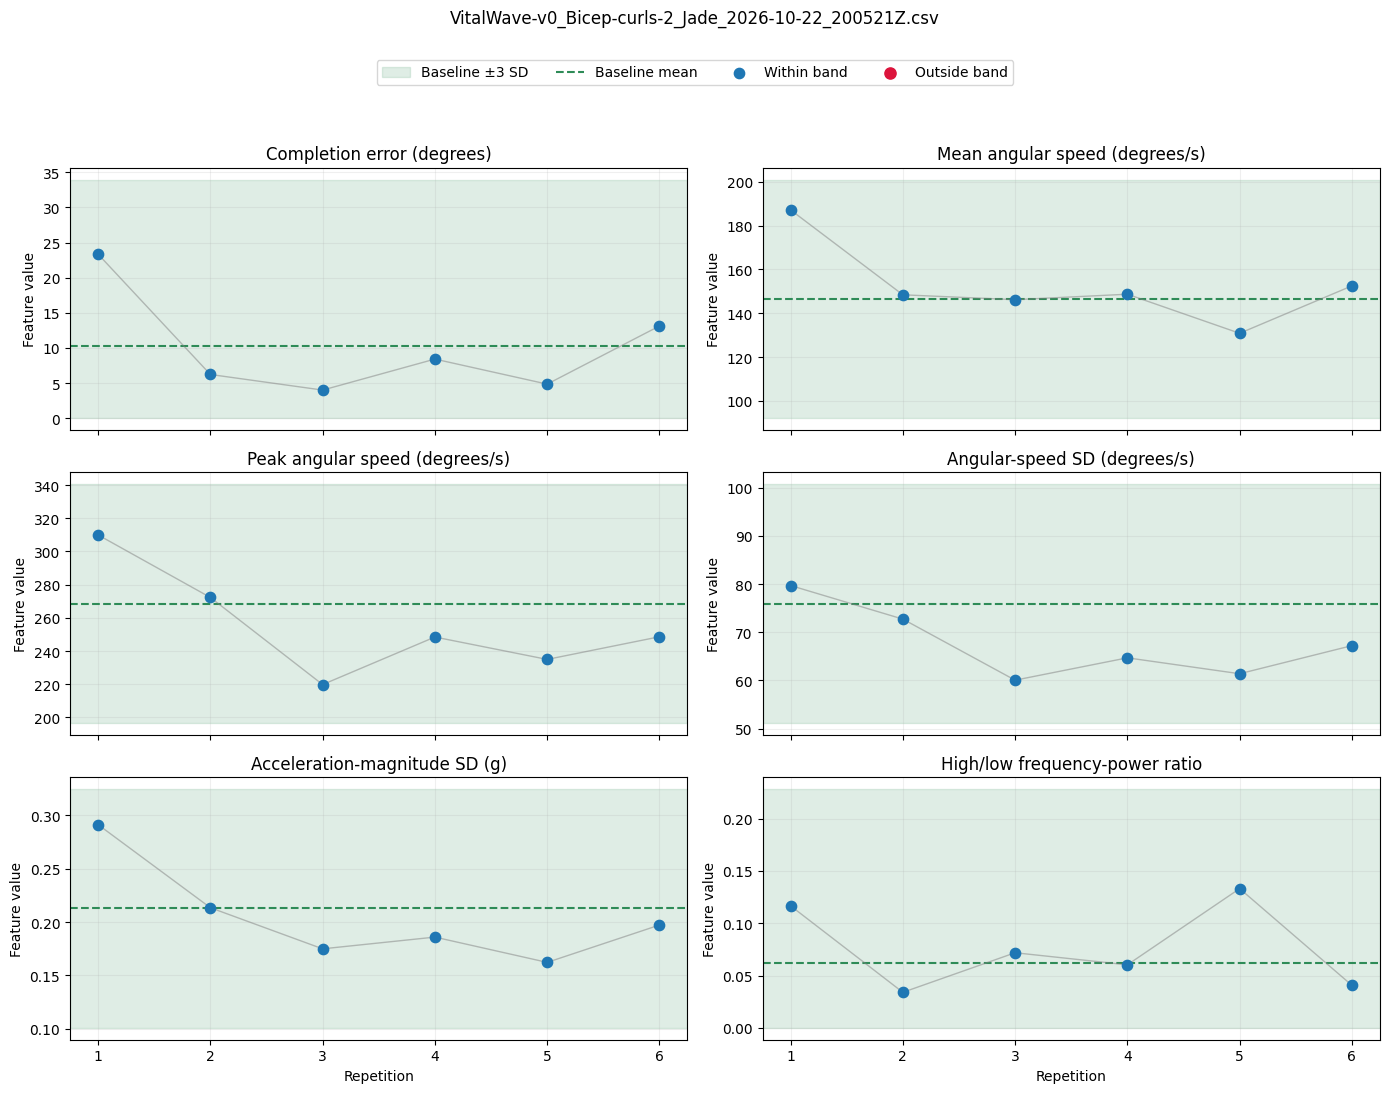

,rep,start_s,end_s,features_outside_band,missing_features
0,1,2.00,3.40,None,None
1,2,3.40,5.52,None,None
2,3,5.52,7.36,None,None
3,4,7.36,9.40,None,None
4,5,9.40,11.68,None,None
5,6,11.68,13.44,None,None



VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-atypical_Jade_2026-10-22_200600Z.csv
  Sensor 1: excluding 29 invalid samples.
  Sensor 1: interpolating 59 short timestamp gap(s).
  Sensor 2: excluding 29 invalid samples.
  Sensor 2: interpolating 59 short timestamp gap(s).
  Timestamp estimate: 50.00 Hz; using a 50 Hz uniform grid.
  Stillness check failed: no gyro bias correction applied.
  Source: ~50.0 Hz; analysis: 25 Hz; 7 candidate reps.


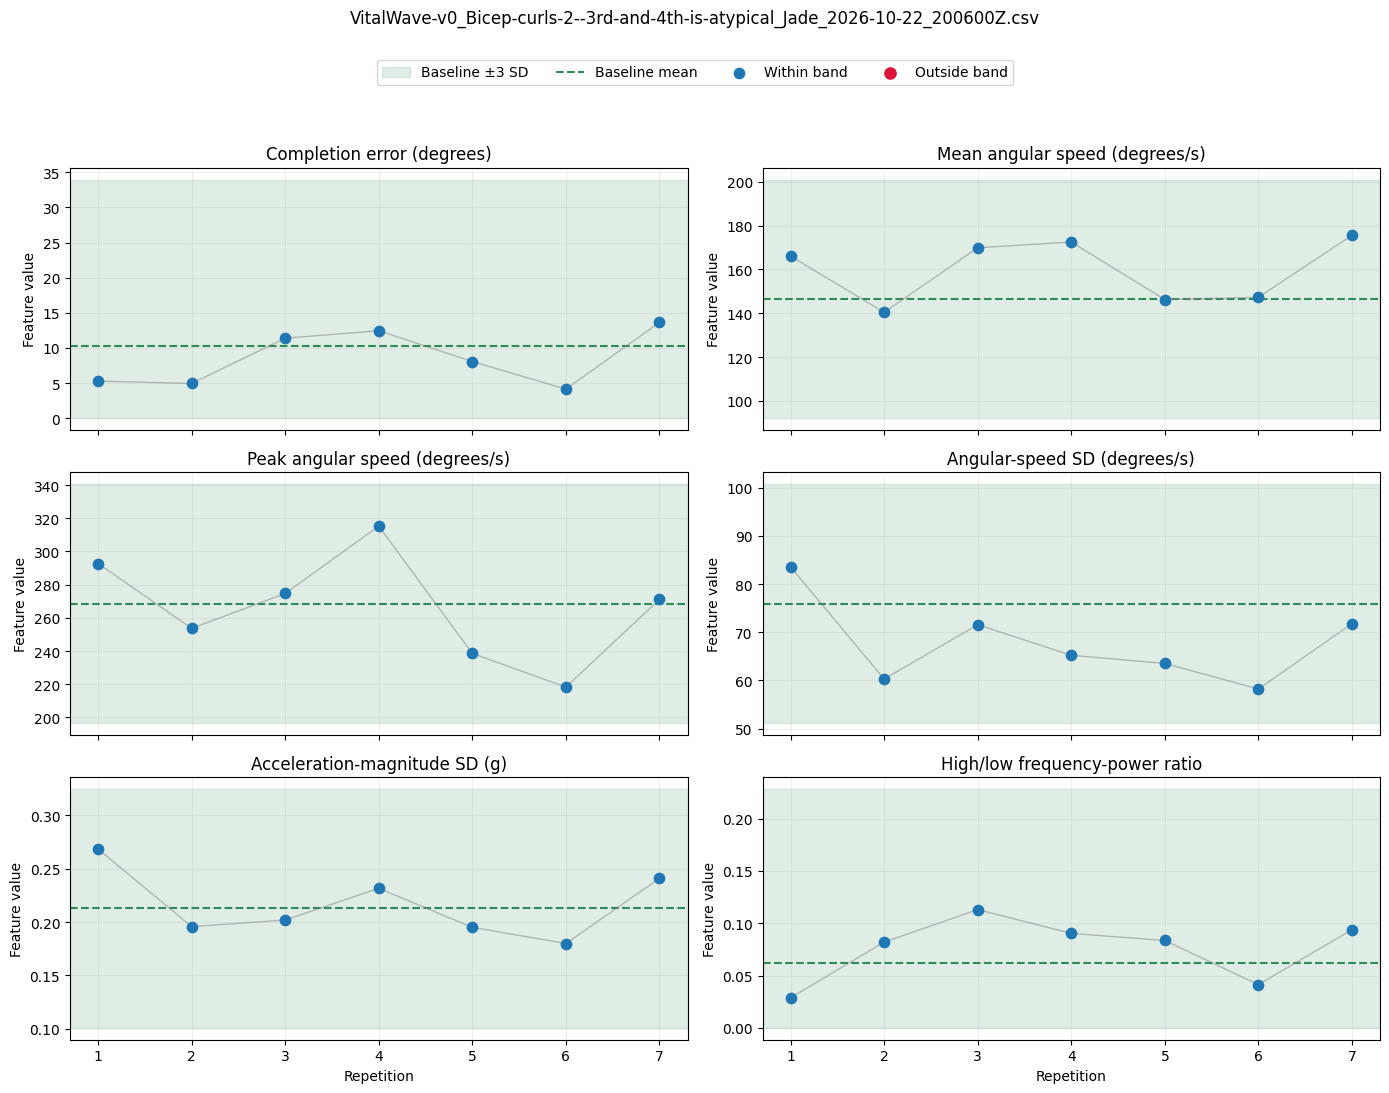

,rep,start_s,end_s,features_outside_band,missing_features
0,1,3.24,4.88,None,None
1,2,4.88,6.76,None,None
2,3,6.76,8.72,None,None
3,4,8.72,10.44,None,None
4,5,10.44,12.36,None,None
5,6,12.36,14.16,None,None
6,7,14.16,15.64,None,None



Red points indicate statistical deviations, not necessarily incorrect exercise. Different recording rates can still affect comparability, especially the frequency-power ratio.


In [14]:
from pathlib import Path
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, periodogram, resample_poly
from scipy.spatial.transform import Rotation
from IPython.display import display

ROOT = Path(
    "/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo"
)

FILES = [
    ROOT / "Data/new_watch/VitalWave-v0_Bicep-curls-2_Jade_2026-10-22_200521Z.csv",
    ROOT / "Data/new_watch/VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-atypical_Jade_2026-10-22_200600Z.csv",
]

BASELINE_PATH = (
    ROOT / "patient-baseline-model/baselines/"
    "patient_baseline_20261022_160422_530014.csv"
)

# Load the original baseline. Do not recalculate it using these recordings.
reference = pd.read_csv(BASELINE_PATH, index_col="feature")

FEATURE_LABELS = {
    "completion_error_deg": "Completion error (degrees)",
    "gyro_mean_deg_s": "Mean angular speed (degrees/s)",
    "gyro_peak_deg_s": "Peak angular speed (degrees/s)",
    "gyro_std_deg_s": "Angular-speed SD (degrees/s)",
    "accel_magnitude_std_g": "Acceleration-magnitude SD (g)",
    "gyro_high_low_power_ratio": "High/low frequency-power ratio",
}
FEATURES = list(FEATURE_LABELS)

if not np.isfinite(
    reference.loc[FEATURES, ["mean", "sd", "lower_3sd", "upper_3sd"]]
    .to_numpy()
).all():
    raise ValueError("Baseline has missing or invalid values.")


def extract_recording_features(csv_path):
    """Same orientation-based approach, with final-rep stillness confirmation."""
    data = pd.read_csv(csv_path)

    if data["protocol_session_id"].nunique() != 1:
        raise ValueError("Expected one recording session.")

    t0 = data["watch_timestamp_ms"].min() / 1000
    streams = {}

    for sensor_type, scale in [(1, 0.000061), (2, 0.00875)]:
        d = data.loc[data["type"] == sensor_type].copy()

        valid = pd.to_numeric(d["validity"], errors="coerce").eq(1)
        print(f"  Sensor {sensor_type}: excluding {(~valid).sum()} invalid samples.")
        d = d.loc[valid].copy()

        if len(d) < 30:
            raise ValueError(f"Sensor {sensor_type}: too few valid samples.")

        ts = d["watch_timestamp_ms"].to_numpy(float) / 1000 - t0
        values = d[["x_raw", "y_raw", "z_raw"]].to_numpy(float) * scale

        if not np.isfinite(values).all() or not np.isfinite(ts).all():
            raise ValueError("Nonfinite data.")
        if np.any(np.diff(ts) <= 0):
            raise ValueError("Duplicate or out-of-order timestamps.")

        dt = np.median(np.diff(ts))
        gaps = np.diff(ts)

        # Allow isolated short gaps, but do not bridge long missing sections.
        if gaps.max() > 2.1 * dt:
            raise ValueError("Large timestamp gap: inspect/split recording first.")

        missing_intervals = np.count_nonzero(gaps > 1.5 * dt)
        if missing_intervals:
            print(
                f"  Sensor {sensor_type}: interpolating "
                f"{missing_intervals} short timestamp gap(s)."
            )

        streams[sensor_type] = (ts, values, dt)

    measured_fs = 1 / streams[2][2]

    # Choose the nearest supported nominal rate, allowing timestamp jitter.
    supported_rates = np.array([25.0, 50.0])
    source_fs = int(
        supported_rates[np.argmin(np.abs(supported_rates - measured_fs))]
    )

    if abs(measured_fs - source_fs) / source_fs > 0.10:
        raise ValueError(
            f"Measured rate {measured_fs:.2f} Hz is too far from "
            f"the supported rates. Inspect timestamps."
        )

    if not np.isclose(streams[1][2], streams[2][2], rtol=0.10):
        raise ValueError("Sensor sampling rates differ substantially.")

    print(
        f"  Timestamp estimate: {measured_fs:.2f} Hz; "
        f"using a {source_fs} Hz uniform grid."
    )
    # Align at the source rate, then anti-alias before reducing 50 Hz to 25 Hz.
    source_t = np.arange(
        max(streams[1][0][0], streams[2][0][0]),
        min(streams[1][0][-1], streams[2][0][-1]) + 1e-8,
        1 / source_fs,
    )

    def align(sensor_type):
        ts, values, _ = streams[sensor_type]
        return np.column_stack([
            np.interp(source_t, ts, values[:, k]) for k in range(3)
        ])

    acc_raw, gyro_raw = align(1), align(2)
    down = source_fs // 25

    if down > 1:
        acc_raw = resample_poly(acc_raw, 1, down, axis=0, padtype="line")
        gyro_raw = resample_poly(gyro_raw, 1, down, axis=0, padtype="line")

    fs = 25.0
    t = source_t[0] + np.arange(len(gyro_raw)) / fs
    keep = t <= source_t[-1] + 1e-8
    t, acc_raw, gyro_raw = t[keep], acc_raw[keep], gyro_raw[keep]

    lead = t < t[0] + 2.0
    still = (
        lead.sum() >= 10
        and np.std(np.linalg.norm(acc_raw[lead], axis=1)) <= 0.03
        and np.max(np.linalg.norm(gyro_raw[lead], axis=1)) <= 5
    )

    if still:
        gyro_raw -= gyro_raw[lead].mean(axis=0)
    else:
        print("  Stillness check failed: no gyro bias correction applied.")

    sos = butter(4, 4.0, fs=fs, btype="lowpass", output="sos")
    acc = sosfiltfilt(sos, acc_raw, axis=0)
    gyro = sosfiltfilt(sos, gyro_raw, axis=0)

    # Orientation estimate.
    x, y, z = acc[0]
    r = Rotation.from_euler(
        "xyz",
        [np.arctan2(y, z), np.arctan2(-x, np.hypot(y, z)), 0],
    )
    r0 = r
    quats, angles = [r.as_quat()], [0.0]

    for i in range(1, len(t)):
        omega = np.deg2rad((gyro[i - 1] + gyro[i]) / 2)
        norm = np.linalg.norm(acc[i])
        if 0.85 <= norm <= 1.15:
            omega += 0.5 * np.cross(
                acc[i] / norm, r.inv().apply([0, 0, 1])
            )
        r = r * Rotation.from_rotvec(omega * (t[i] - t[i - 1]))
        quats.append(r.as_quat())
        angles.append(np.rad2deg((r0.inv() * r).magnitude()))

    quats = np.asarray(quats)
    history = deque(maxlen=max(1, round(0.1 * fs)))
    excursion = []
    for angle in angles:
        history.append(angle)
        excursion.append(np.mean(history))
    excursion = np.asarray(excursion)
    speed = np.linalg.norm(gyro, axis=1)

    # Same trough-to-trough detector.
    mode, low, high, start = "seek", None, None, None
    candidates = []

    for i in np.flatnonzero(~lead):
        value = excursion[i]
        if low is None:
            low = (i, value)
            continue

        if mode in ("seek", "rise"):
            if value < low[1]:
                low = (i, value)
            if mode == "seek" and value - low[1] >= 15:
                start, high, mode = low[0], (i, value), "rise"
            elif mode == "rise":
                if high is None or value > high[1]:
                    high = (i, value)
                if high[1] - value >= 8:
                    low, mode = (i, value), "fall"
        else:
            if value < low[1]:
                low = (i, value)
            if value - low[1] >= 8:
                candidates.append((start, low[0]))
                start, high, mode = low[0], (i, value), "rise"

    # Trim idle time before the first confirmed rep.
    rest_speed = speed[lead]
    onset = max(
        10.0,
        np.median(rest_speed)
        + 6 * np.median(np.abs(rest_speed - np.median(rest_speed))),
    )

    if candidates:
        a, b = candidates[0]
        hold = max(2, int(np.ceil(0.12 * fs)))
        for k in range(a, b - hold + 1):
            if np.all(speed[k:k + hold] > onset):
                candidates[0] = (max(a, k - 1), b)
                break

    # Final rep: return near start + 0.5 s sustained low speed.
    if start is not None and mode == "fall" and high is not None:
        peak_i, peak_value = high
        settled = (
            (np.abs(excursion - excursion[start]) <= 15)
            & (peak_value - excursion >= 8)
            & (speed <= 15)
        )
        settle_start = None

        if peak_value - excursion[start] >= 15:
            for i in range(peak_i + 1, len(t)):
                if settled[i]:
                    if settle_start is None:
                        settle_start = i
                    if t[i] - t[settle_start] >= 0.5:
                        candidates.append((start, settle_start))
                        start = None
                        break
                else:
                    settle_start = None

    rows = []
    for a, b in candidates:
        if not 0.6 <= t[b] - t[a] <= 8:
            continue
        if np.ptp(excursion[a:b + 1]) < 15:
            continue

        section = slice(a, b + 1)
        rep_speed = speed[section]

        error = np.rad2deg(
            (
                Rotation.from_quat(quats[a]).inv()
                * Rotation.from_quat(quats[b])
            ).magnitude()
        )

        # Before the 4 Hz smoothing, but after any anti-alias resampling.
        freq, power = periodogram(
            np.linalg.norm(gyro_raw[section], axis=1),
            fs=fs,
            window="hann",
            detrend="constant",
            scaling="spectrum",
        )
        low_power = power[(freq >= 0.1) & (freq <= 2)].sum()
        high_power = power[(freq >= 3) & (freq <= 8)].sum()

        rows.append({
            "rep": len(rows) + 1,
            "start_s": t[a],
            "end_s": t[b],
            "completion_error_deg": error,
            "gyro_mean_deg_s": rep_speed.mean(),
            "gyro_peak_deg_s": rep_speed.max(),
            "gyro_std_deg_s": rep_speed.std(),
            "accel_magnitude_std_g": np.linalg.norm(
                acc[section], axis=1
            ).std(),
            "gyro_high_low_power_ratio": (
                high_power / low_power if low_power > 1e-12 else np.nan
            ),
        })

    print(
        f"  Source: ~{measured_fs:.1f} Hz; analysis: 25 Hz; "
        f"{len(rows)} candidate reps."
    )
    if start is not None:
        print("  Unconfirmed final movement excluded; inspect segmentation.")

    return pd.DataFrame(
        rows, columns=["rep", "start_s", "end_s"] + FEATURES
    )


# Analyze and plot each file independently.
comparison_results = {}

for file_path in FILES:
    print(f"\n{file_path.name}")
    reps = extract_recording_features(file_path)

    if reps.empty:
        print("No repetitions detected.")
        continue

    values = reps.set_index("rep")[FEATURES]
    lower = reference.loc[FEATURES, "lower_3sd"]
    upper = reference.loc[FEATURES, "upper_3sd"]
    means = reference.loc[FEATURES, "mean"]
    sd = reference.loc[FEATURES, "sd"]

    flags = values.lt(lower, axis="columns") | values.gt(upper, axis="columns")
    z_scores = values.subtract(means, axis="columns").divide(
        sd.replace(0, np.nan), axis="columns"
    )

    summary = reps[["rep", "start_s", "end_s"]].copy()
    summary["features_outside_band"] = [
        ", ".join(flags.columns[row.to_numpy()]) or "None"
        for _, row in flags.iterrows()
    ]
    summary["missing_features"] = [
        ", ".join(values.columns[row.to_numpy()]) or "None"
        for _, row in values.isna().iterrows()
    ]

    comparison_results[file_path.name] = {
        "features": reps,
        "flags": flags,
        "z_scores": z_scores,
        "summary": summary,
    }

    fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)

    for ax, feature in zip(axes.flat, FEATURES):
        y = values[feature]
        outside = flags[feature]

        ax.axhspan(
            lower[feature], upper[feature],
            color="seagreen", alpha=0.15, label="Baseline ±3 SD",
        )
        ax.axhline(
            means[feature],
            color="seagreen", linestyle="--", label="Baseline mean",
        )
        ax.plot(
            values.index, y, color="gray", linewidth=1, alpha=0.5
        )
        ax.scatter(
            values.index[~outside], y[~outside],
            color="tab:blue", s=55, zorder=3, label="Within band",
        )
        ax.scatter(
            values.index[outside], y[outside],
            color="crimson", s=65, zorder=4, label="Outside band",
        )

        ax.set_title(FEATURE_LABELS[feature])
        ax.set_ylabel("Feature value")
        ax.set_xticks(values.index)
        ax.grid(alpha=0.2)

    for ax in axes[-1]:
        ax.set_xlabel("Repetition")

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center",
        bbox_to_anchor=(0.5, 0.95), ncol=4,
    )
    fig.suptitle(file_path.name, fontsize=12, y=0.99)
    fig.tight_layout(rect=[0, 0, 1, 0.91])
    plt.show()

    display(summary.round(2))

print(
    "\nRed points indicate statistical deviations, not necessarily incorrect "
    "exercise. Different recording rates can still affect comparability, "
    "especially the frequency-power ratio."
)